# Splane&Scube tutorial (2/2): Alignment of consecutive ST slices on human brain MERFISH dataset

Dataset: 33 MERFISH slices of mouse brain ([here](https://zenodo.org/record/8167488))

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
import SPACEL
from SPACEL import Scube

In [4]:
seed = 1

## Spatial transcriptomic data import

The input data type of Scube is a list of anndata objects for each slice. The anndata objects of each slice must contain a column of spatial domain for alignment in ``.obs``.

In [ ]:
adata = sc.read(f'./{seed}/merfish_mouse_brain.h5ad')
adata[0]

View of AnnData object with n_obs × n_vars = 1 × 254
    obs: 'sample_id', 'slice_id', 'class_label', 'subclass', 'label', 'Astro_1', 'Endo', 'SMC', 'L23_IT_3', 'VLMC', 'L6_CT_5', 'L45_IT_2', 'L45_IT_SSp_2', 'Peri', 'L5_ET_1', 'L45_IT_1', 'L45_IT_5', 'L45_IT_3', 'L23_IT_4', 'L5_IT_1', 'Micro_1', 'L23_IT_2', 'L5_ET_5', 'Sst_3', 'L6_IT_3', 'Oligo_1', 'L5_ET_4', 'Sncg_1', 'L6_IT_Car3', 'Vip_7', 'PVM', 'L5_ET_3', 'L56_NP_1', 'Pvalb_6', 'L6_CT_3', 'L5_IT_2', 'L6_CT_1', 'L45_IT_SSp_1', 'Astro_2', 'Pvalb_5', 'L56_NP_2', 'Oligo_2', 'L6_IT_1', 'L6_CT_2', 'Pvalb_3', 'OPC', 'striatum_1', 'L5_IT_3', 'L23_IT_1', 'Oligo_3', 'Pvalb_4', 'Vip_1', 'L23_IT_5', 'L6_CT_6', 'Pvalb_1', 'Pvalb_7', 'L5_IT_4', 'L6b_2', 'L6_CT_4', 'Vip_3', 'Vip_10', 'striatum_2', 'Sst_2', 'L6_IT_2', 'L6b_1', 'L6_CT_8', 'Pvalb_10', 'L5_ET_2', 'L6_CT_7', 'Micro_2', 'L45_IT_4', 'Sst_1', 'Pvalb_2', 'Vip_6', 'Lamp5_1', 'L6b_3', 'ventricle_1', 'Lamp5_5', 'Sncg_2', 'Sst_6', 'Vip_8', 'Sst_5', 'Sst_4', 'Astro_3', 'Vip_2', 'Pvalb_8', 'Lam

In [6]:
slices = ['mouse1_slice1', 'mouse1_slice10', 'mouse1_slice21', 'mouse1_slice31', 'mouse1_slice40', 'mouse1_slice50', 'mouse1_slice62',
 'mouse1_slice71', 'mouse1_slice81', 'mouse1_slice91', 'mouse1_slice102', 'mouse1_slice112', 'mouse1_slice122', 'mouse1_slice131', 'mouse1_slice153',
 'mouse1_slice162', 'mouse1_slice170', 'mouse1_slice180', 'mouse1_slice190', 'mouse1_slice200', 'mouse1_slice201', 'mouse1_slice212',
 'mouse1_slice221', 'mouse1_slice232', 'mouse1_slice241', 'mouse1_slice251', 'mouse1_slice260', 'mouse1_slice271', 'mouse1_slice283',
 'mouse1_slice291', 'mouse1_slice301', 'mouse1_slice313', 'mouse1_slice326']
adata_list=[]
for i in range(33):
    adata_list.append(adata[adata.obs['slice_id'] == slices[i]])
    adata_list[i].uns['spatial_domain_colors'] = pd.Series(np.unique(adata_list[i].obs.spatial_domain)).replace(dict(zip([4,1,6,2,3,5,0],['#aad466', '#f4ed27','#f9973f','#e76f5a','#40ecd4', '#a62098', '#a4bcda']))).values.flatten()
    adata_list[i].obs.spatial_domain = adata_list[i].obs.spatial_domain.astype('category')

Plot all raw slices stacked in a single figure. Cells colored by spatial domain.First, we define the color of each spatial domain.

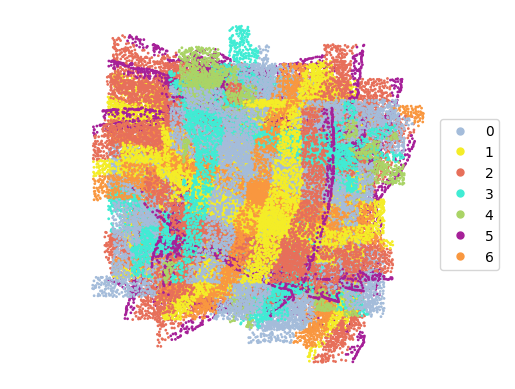

In [7]:
Scube.plot_stacked_slices(adata_list,spatial_key='spatial',cluster_key='spatial_domain')

## Pairwise alignment

Here, we perform pairwise alignment of slices. The ``cluster_key`` is a column of ``.obs`` which contain spatial domain information used for alignment. The ``n_neighbors`` affect how much neighbors are considered when calculate similarity of two slices. The ``knn_exclude_cutoff`` affect max distance of neighbors. By default, ``n_neighbors = 15`` and ``knn_exclude_cutoff = n_neighbors`` means a spot/cell in source slices consider 15 neighbors in target slices, and neighbor will be exclude when the distance of neighbors larger than the median of neareast 30 neighbors distance in all spot/cell in target slice. ``p`` affect the exponent of overlap penalty, and a larger p means stronger partial alignment capability.

In [ ]:
Scube.align(adata_list,
      cluster_key='spatial_domain', 
      n_neighbors = 15, 
      n_threads=10,
      p=2,
      seed=seed,
     )

Start alignment...
Alignment slice 1 to 0
Alignment slice 2 to 1
Alignment slice 3 to 2
Alignment slice 4 to 3
Alignment slice 5 to 4
Alignment slice 6 to 5
Alignment slice 7 to 6
Alignment slice 8 to 7
Alignment slice 9 to 8
Alignment slice 10 to 9
Alignment slice 11 to 10
Alignment slice 12 to 11
Alignment slice 13 to 12
Alignment slice 14 to 13
Alignment slice 15 to 14
Alignment slice 16 to 15
Alignment slice 17 to 16
Alignment slice 18 to 17
Alignment slice 19 to 18
Alignment slice 20 to 19
Alignment slice 21 to 20
Alignment slice 22 to 21
Alignment slice 23 to 22
Alignment slice 24 to 23
Alignment slice 25 to 24
Alignment slice 26 to 25
Alignment slice 27 to 26
Alignment slice 28 to 27
Alignment slice 29 to 28
Alignment slice 30 to 29
Alignment slice 31 to 30
Alignment slice 32 to 31
Runtime: 9051.91582775116 s


After alignment, the new spots/cells location coordinates saved in ``.obsm['spatial_aligned']`` of anndata object of each slices. When ``write_loc_path`` provied by users, the location coordinates of all spots/cells of all slices will be saved in ``write_loc_path``.

## LAA & ARI

In [9]:
from sklearn.metrics import pairwise
from sklearn.metrics import adjusted_rand_score

def cal_layer_based_alignment_result_mHypothalamus(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    #l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    ir = 0
    max_smallerThan0 = []
    sum_smallerThan0 = []
    min_smallerThan0 = []

    for i, elem in enumerate(alignment):
        #if np.sum(elem)>0:
        if np.max(elem) - np.min(elem) != 0:
            if labels[i] == labels[elem.argmax() + alignment.shape[0]]:
                cnt0 += 1
        else:
            ir += 1
            max_smallerThan0.append(np.max(elem))
            sum_smallerThan0.append(np.sum(elem))
            min_smallerThan0.append(np.min(elem))
#     print("the number of sum alignment equals 0:", str(ir))
#     if len(sum_smallerThan0)>0:
#         print("sum in sum alignment equals 0 is between", np.min(sum_smallerThan0), np.max(sum_smallerThan0))
#         print("max in sum alignment equals 0 is between", np.min(max_smallerThan0), np.max(max_smallerThan0))
#         print("min in sum alignment equals 0 is between", np.min(min_smallerThan0), np.max(min_smallerThan0))

    res.extend([cnt0])
    return res


def compute_alignment_ari(pi, sliceA, sliceB):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [ ]:
ari_values = []
laa_values = []

for i in range(1, len(slices)):
    target_ind = i-1
    source_ind = i
    f1 = adata_list[target_ind].obsm['spatial_aligned'].to_numpy()
    f2 = adata_list[source_ind].obsm['spatial_aligned'].to_numpy()

    alignment = pairwise.euclidean_distances(f1, f2)
    alignment = np.exp(-alignment)
    
    # Save as .pkl
    alignment_df = pd.DataFrame(alignment)
    alignment_df.to_pickle(f'./{seed}/{target_ind}_{source_ind}_AlignmentPi.pkl')
    
    res = cal_layer_based_alignment_result_mHypothalamus(alignment, adata_list[target_ind], adata_list[source_ind])
    laa = res[0]/len(adata_list[source_ind].obs['original_clusters'])
    ari = compute_alignment_ari(alignment, adata_list[target_ind], adata_list[source_ind])
    ari_values.append(ari)
    laa_values.append(laa)
    print(laa, ari)

# Create DataFrame with desired format
header_row = [f"{i-1}_{i}" for i in range(1, len(slices))]
ari_df = pd.DataFrame([ari_values], columns=header_row)
laa_df = pd.DataFrame([laa_values], columns=header_row)

0.2323565827486587 0.7809336549404514
0.2439744220363994 0.7672883337945166
0.15003219575016097 0.6974340288608968
0.1598942053378216 0.8028061372115105
0.1961459050240881 0.8023285462780528
0.1815525876460768 0.7761369437238262
0.1647242998782397 0.7945331259253494
0.19954389965792474 0.8447466486703669
0.16481187069422362 0.8212010703768827
0.166097162383004 0.8408508757524052
0.22858286629303443 0.8857509093429353
0.1618431689571544 0.8060165291055483
0.1956135151155898 0.7947838819038466
0.11618148439548912 0.736632813694158
0.18540858825219014 0.8233614470905715
0.18160705991639572 0.8008471669484737
0.14926564495530012 0.7758076423525021
0.15881326352530542 0.7969839331763005
0.18707328174783797 0.7824908152478649
0.06063042779028627 0.7659882331392784
0.16893649579188982 0.7778601793170645
0.1816762103071317 0.7600981118054072
0.18641860465116278 0.797553373081798
0.16855873642645608 0.7595406344448132
0.14743734477308648 0.8038925132048872
0.12428198433420365 0.8135816007019178

In [ ]:
# Save as a CSV file
ari_df.to_csv(f'./{seed}/merfish_ARI.csv')
laa_df.to_csv(f'./{seed}/merfish_LAA.csv')

## Plot alignment results

Save all spots/cells aligned coordiantes and colors in a DataFrame.

In [12]:
import matplotlib.pyplot as plt
import matplotlib

# Combine unique clusters from all slices
unique_clusters = adata_list[20].obs['original_clusters'].unique()
sorted_clusters = np.sort(unique_clusters)

cmap = []
if len(sorted_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=60
    colormaps = ['tab20', 'tab20b', 'tab20c']
    for cmap_name in colormaps:
        for color in plt.get_cmap(cmap_name).colors:
            cmap.append(matplotlib.colors.rgb2hex(color))

# Create the dictionary with the combined clusters
c_dict = dict(zip(sorted_clusters, cmap))
c_dict

{0: '#1f77b4',
 1: '#ff7f0e',
 2: '#2ca02c',
 3: '#d62728',
 4: '#9467bd',
 5: '#8c564b',
 6: '#e377c2'}

In [ ]:
coo = pd.DataFrame()
for i in range(len(adata_list)):
    loc = adata_list[i].obsm['spatial_aligned'].copy()
    loc['Z'] = i
    loc['slice'] = adata_list[i].obs['slice_id']
    loc['original_clusters'] = adata_list[i].obs['original_clusters']
    loc['celltype_colors'] = adata_list[i].obs['original_clusters'].replace(c_dict)
    coo = pd.concat([coo,loc],axis=0)
    
coo.to_csv(f'./{seed}/SPACEL_merfish_aligned_coordinates_colors.csv')

In [ ]:
coo

,X,Y,Z,slice,original_clusters,celltype_colors
100023173600007776283900355785793185282,141.201416,294.315430,0,mouse1_slice1,2,#2ca02c
100357557613983092542421396030726393144,-416.779541,580.392456,0,mouse1_slice1,1,#ff7f0e
100438314633131300286240527528820911794,43.212158,-257.781494,0,mouse1_slice1,6,#e377c2
100689500727523367948135048603789232105,-460.539551,431.271729,0,mouse1_slice1,1,#ff7f0e
100756095765922513431551474967095417597,262.594727,60.847656,0,mouse1_slice1,5,#8c564b
...,...,...,...,...,...,...
99313655668851798305862075572360852245,389.936310,2706.028320,32,mouse1_slice326,1,#ff7f0e
99362714030907400558551694843706883556,732.987976,3075.278076,32,mouse1_slice326,1,#ff7f0e
99434568482370616061094992947385476620,1433.022217,2457.734131,32,mouse1_slice326,4,#9467bd
99456067362493193970419180381005240507,872.948914,2744.752441,32,mouse1_slice326,1,#ff7f0e


Plot all aligned slices stacked in 3D constructed by Scube

In [ ]:
def plot_3d(
    loc,
    val=None,
    color=None,
    figsize=(12,12),
    return_fig=True,
    elev=None,
    azim=None,
    roll=None,
    xlim=None,
    ylim=None,
    zlim=None,
    frameon=True,
    save_path=None,
    save_dpi=150,
    show=True,
    *args,
    **kwargs
):
    """Plot all slices stacked in 3D

    Plot all slices stacked with a given number of subplots rows and columns. Spots/cells colored by spatial domain.

    Args:
        loc: An array of the coordinates of each spots/cells in all slices, which the first three columns are X-axis, Y-axis, Z-axis coordinates.
        val: The colors of each spots/cells given in loc use to plot.
        color: The colors of each spots/cells given in loc use to plot.
        figsize: Size of the figure.
        return_fig: Whether to return the figure.
        elev: The elevation angle in the vertical plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        azim: The azimuth angle in the horizontal plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        xlim: A tuple given the left and right xlims in X-axis.
        ylim: A tuple given the left and right xlims in Y-axis.
        zlim: A tuple given the left and right xlims in Z-axis.
        frameon: Whether to hide the coordinate axes.
        save_path: A string representing the path directory where the figure saved.
        save_dpi: The resolution in dots per inch.
        show: Whether to show the figure.

    Returns:
        A ``matplotlib.figure.Figure`` object
    """
    if 'marker' not in kwargs.keys():
        kwargs['marker'] = 'o'
    if 's' not in kwargs.keys():
        kwargs['s'] = 5
    if 'cmap' not in kwargs.keys():
        kwargs['cmap'] = 'Spectral_r'
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(projection='3d')
    if (elev is not None) and (azim is not None) and (roll is not None):
        ax.view_init(elev, azim, roll)
    if color is None:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=val,*args,**kwargs)
    else:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=color,*args,**kwargs)
    
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    if not frameon:
        plt.axis('off')
        plt.grid(b=None)
    if save_path is not None:
        print(save_path)
        plt.savefig(save_path,dpi=save_dpi,bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close()
    if return_fig:
        return fig

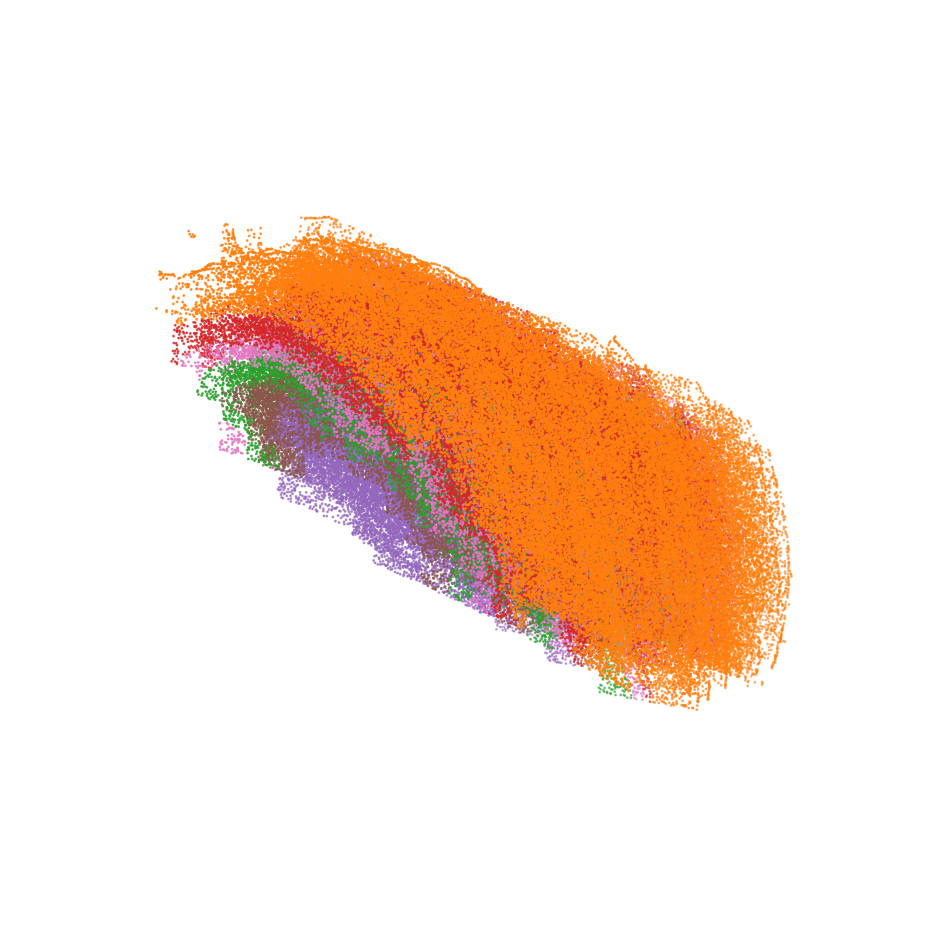

In [ ]:
fig = plot_3d(coo.values[:,:3],val=None,color=coo['celltype_colors'],show=True,frameon=False,elev=230,azim=60,roll=110,s=1,return_fig=True)

fig.savefig(f'./{seed}/SPACEL_gtAndScube_merfish_3dviz_angle220_120_1128_24_s=1.pdf', bbox_inches="tight")